# การทำนายค่า MOID ของดาวเคราะห์น้อยด้วย Machine Learning (Regression)

**เป้าหมาย:** ทำนาย Minimum Orbit Intersection Distance (MOID) ระหว่างวงโคจรของดาวเคราะห์น้อยกับวงโคจรของโลก โดยรายงานผลเป็นหน่วย Astronomical Unit (AU)

> **ก่อนเริ่ม:** Notebook นี้อ้างอิงกระบวนการจาก `train.py` ของโครงงาน ใช้ไฟล์ `data/asteroid.csv` และบันทึกโมเดลลง `model/moid_model.joblib` ต้องรันเซลล์ตามลำดับทั้งหมดบนเครื่องที่มีไฟล์ CSV อยู่จริง

**ข้อจำกัดในการตีความ:** MOID ไม่ใช่ความน่าจะเป็นในการชนโลก และผลจากแบบจำลองนี้ไม่ใช่การประเมินความเสี่ยงการชนอย่างเป็นทางการ

## 1. ปัญหาและเป้าหมายของโครงงาน

โครงงานนี้เป็นปัญหา **Supervised Learning ประเภท Regression** เพราะต้องเรียนรู้จากตัวอย่างที่มีค่าเป้าหมายเป็นตัวเลขต่อเนื่อง

- **ตัวแปรเป้าหมาย:** `moid` (AU)
- **ตัวแปรนำเข้า 8 ตัว:** `H`, `albedo`, `e`, `a`, `i`, `om`, `w`, `ma`
- **การใช้งาน:** ทดลองศึกษาว่าคุณลักษณะทางกายภาพและวงโคจรสัมพันธ์กับค่า MOID ที่ทำนายอย่างไร
- **ตัวชี้วัด:** MAE, RMSE และ R² โดยใช้ MAE เป็นตัวช่วยอธิบายขนาดข้อผิดพลาด และเปรียบเทียบโมเดลตาม RMSE ให้สอดคล้องกับ `train.py`

### แหล่งข้อมูล
ระบุชื่อแหล่งข้อมูลต้นฉบับและ URL ที่ใช้จริงก่อนส่งรายงาน: (https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset)
ชื่อไฟล์ในเครื่อง: `data/asteroid.csv`

## 2. ติดตั้งและนำเข้าไลบรารี

หากยังไม่ได้ติดตั้งไลบรารี ให้รันคำสั่งใน Terminal: `pip install -r requirements.txt` จากโฟลเดอร์โปรเจกต์

In [52]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("data/asteroid.csv")
MODEL_DIR = Path("model")
OUTPUT_DIR = Path("outputs")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "moid"
FEATURES = ["H", "albedo", "e", "a", "i", "om", "w", "ma"]
REQUIRED_COLUMNS = FEATURES + [TARGET]

TEST_SIZE = 0.20
RANDOM_STATE = 42
MAX_TREE_TRAIN_ROWS = 150_000

## 3. โหลดชุดข้อมูลและตรวจสอบโครงสร้าง

เซลล์นี้จะหยุดทำงานหากไม่พบไฟล์ CSV หรือคอลัมน์ที่จำเป็น เพื่อป้องกันการฝึกโมเดลด้วยข้อมูลผิดชุด

In [53]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"ไม่พบไฟล์ {DATA_PATH}. กรุณาวาง asteroid.csv ไว้ในโฟลเดอร์ data/"
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"จำนวนแถวเริ่มต้น: {len(df_raw):,}")
print(f"จำนวนคอลัมน์: {df_raw.shape[1]:,}")
display(df_raw.head())

จำนวนแถวเริ่มต้น: 958,524
จำนวนคอลัมน์: 45


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [54]:
missing_columns = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"ไม่พบคอลัมน์ที่จำเป็น: {missing_columns}")

print("พบคอลัมน์ที่จำเป็นครบทั้งหมด")
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "missing_count": df_raw.isna().sum().values
}).head(30))

พบคอลัมน์ที่จำเป็นครบทั้งหมด


,column,dtype,missing_count
0,id,str,0
1,spkid,int64,0
2,full_name,str,0
3,pdes,object,0
4,name,str,936460
5,prefix,str,958506
6,neo,str,4
7,pha,str,19921
8,H,float64,6263
9,diameter,float64,822315


## 4. ทำความสะอาดข้อมูล

ขั้นตอนนี้แปลงคอลัมน์ที่ใช้เป็นตัวเลข ตัดแถวที่ไม่มีค่าเป้าหมายหรือมี MOID ติดลบ ลบแถวซ้ำ และตัดแถวที่ตัวแปรนำเข้าหายทั้งหมด

ค่าที่หายไปบางส่วนในตัวแปรนำเข้าจะยังเก็บไว้ แล้วให้ `SimpleImputer(strategy="median")` จัดการภายหลัง โดยคำนวณค่ามัธยฐานจากชุดฝึกเท่านั้น

In [55]:
df = df_raw[REQUIRED_COLUMNS].copy()

for column in REQUIRED_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

rows_before = len(df)
df = df[df[TARGET].notna()]
df = df[df[TARGET] >= 0]
rows_after_target_cleaning = len(df)

duplicates_before = len(df)
df = df.drop_duplicates()
duplicates_removed = duplicates_before - len(df)

df = df.dropna(subset=FEATURES, how="all")

print(f"แถวก่อนทำความสะอาด: {rows_before:,}")
print(f"แถวที่เหลือหลังตรวจ target: {rows_after_target_cleaning:,}")
print(f"จำนวนแถวซ้ำที่ลบ: {duplicates_removed:,}")
print(f"แถวสุดท้ายหลังทำความสะอาด: {len(df):,}")
print(f"จำนวนคอลัมน์ที่ใช้: {len(REQUIRED_COLUMNS)}")
display(df.head())

แถวก่อนทำความสะอาด: 958,524
แถวที่เหลือหลังตรวจ target: 938,603
จำนวนแถวซ้ำที่ลบ: 0
แถวสุดท้ายหลังทำความสะอาด: 938,603
จำนวนคอลัมน์ที่ใช้: 9


,H,albedo,e,a,i,om,w,ma,moid
0,3.40,0.0900,0.076009,2.769165,10.594067,80.305531,73.597695,77.372098,1.59478
1,4.20,0.1010,0.229972,2.773841,34.832932,173.024741,310.202392,144.975675,1.23429
2,5.33,0.2140,0.256936,2.668285,12.991043,169.851482,248.066193,125.435355,1.03429
3,3.00,0.4228,0.088721,2.361418,7.141771,103.810804,150.728541,95.861938,1.13948
4,6.90,0.2740,0.190913,2.574037,5.367427,141.571026,358.648418,17.846343,1.09575


## 5. สำรวจข้อมูล (EDA)

เพื่อไม่ให้กราฟช้าเกินไปกับชุดข้อมูลขนาดใหญ่ กราฟการกระจายจะสุ่มตัวอย่างได้ไม่เกิน 50,000 แถว ส่วนสถิติสรุปและการตรวจ missing values ใช้ข้อมูลที่ทำความสะอาดแล้วทั้งหมด

In [56]:
missing_summary = df[REQUIRED_COLUMNS].isna().sum().rename("missing_count").to_frame()
display(missing_summary)
display(df[REQUIRED_COLUMNS].describe().T)

df[REQUIRED_COLUMNS].describe().to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv",
    index=True
)

,missing_count
H,6262
albedo,803500
e,0
a,0
i,0
om,0
w,0
ma,1
moid,0


,count,mean,std,min,25%,50%,75%,max
H,932341.0,16.889969,1.801386,-1.100000e+00,16.000000,16.900000,17.700000,33.200000
albedo,135103.0,0.130627,0.110323,1.000000e-03,0.053000,0.079000,0.190000,1.000000
e,938603.0,0.156146,0.093006,0.000000e+00,0.092064,0.144865,0.200598,1.855356
a,938603.0,2.906752,40.137750,-1.470245e+04,2.388114,2.647342,3.002579,33488.895955
i,938603.0,9.048065,6.646721,7.744220e-03,4.154593,7.404507,12.398180,175.082901
om,938603.0,168.449643,102.874452,2.451052e-05,80.565903,159.897335,252.182070,359.999793
w,938603.0,181.383329,103.907129,1.299944e-04,91.487831,182.365333,271.554104,359.999646
ma,938602.0,177.198278,105.859245,-7.070368e+01,83.607833,175.280884,269.853803,491.618014
moid,938603.0,1.415162,2.156731,4.544120e-07,0.979702,1.240850,1.593370,79.476600


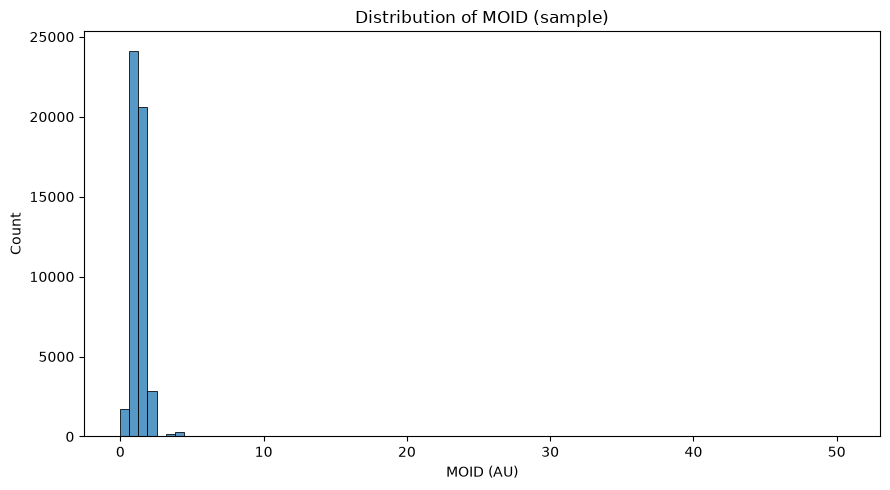

In [57]:
eda_df = df.sample(n=min(len(df), 50_000), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 5))
sns.histplot(data=eda_df, x=TARGET, bins=80)
plt.title("Distribution of MOID (sample)")
plt.xlabel("MOID (AU)")
plt.tight_layout()
plt.show()

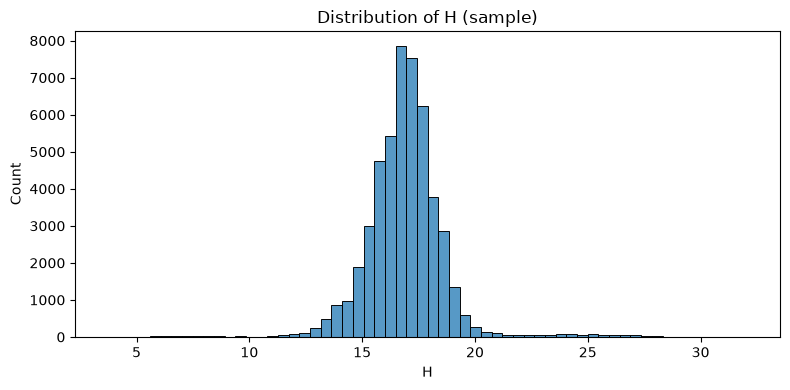

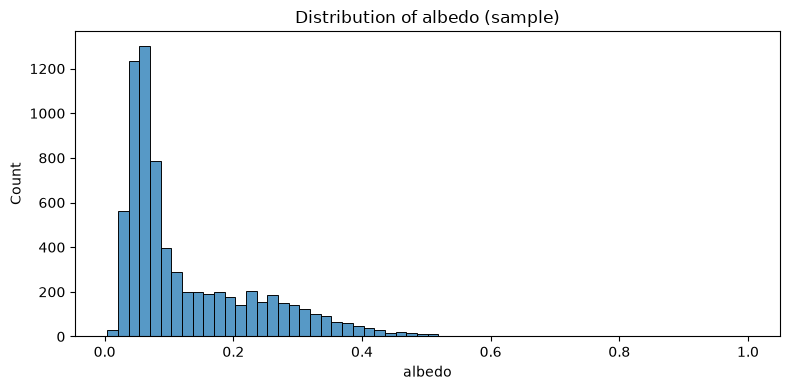

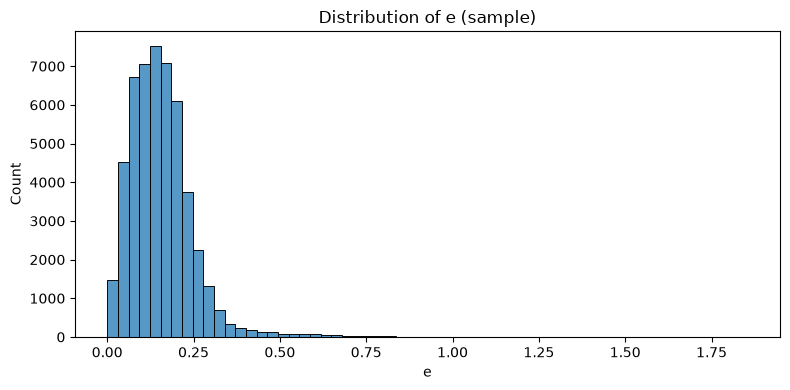

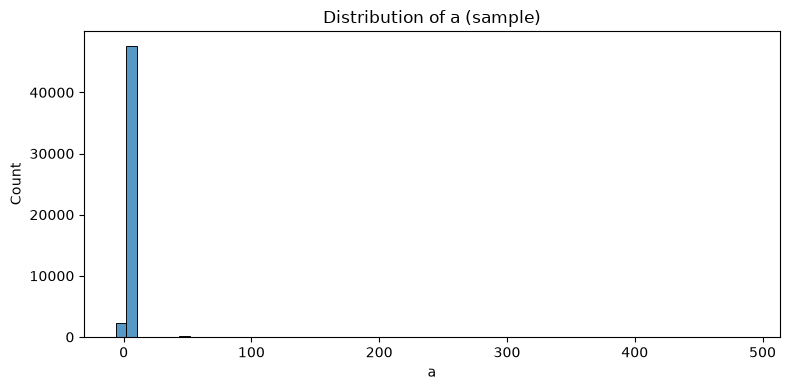

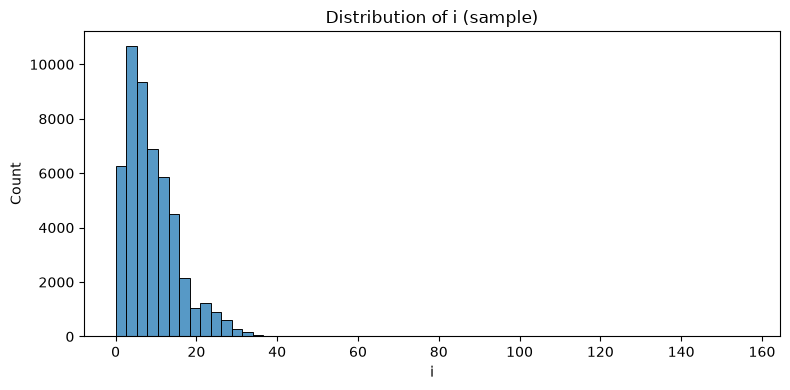

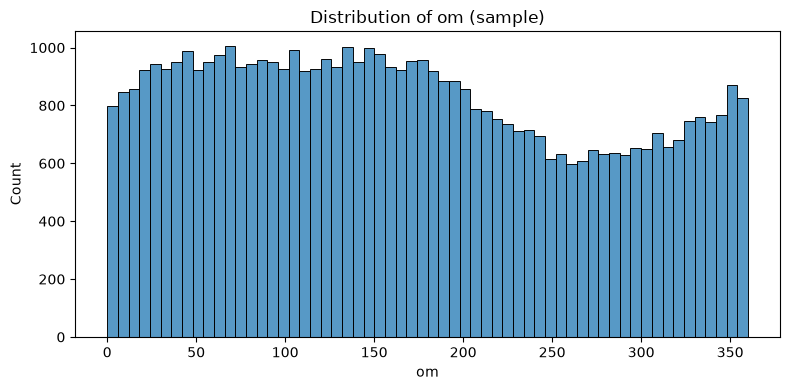

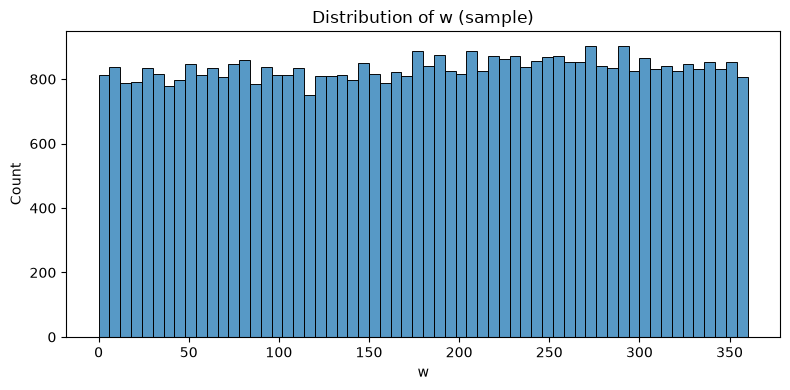

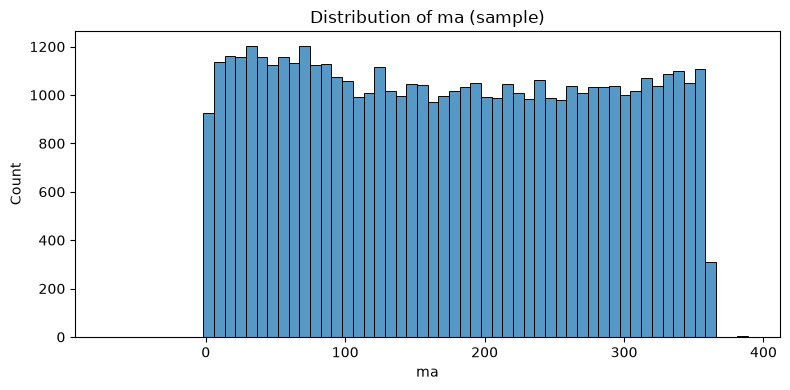

In [41]:
for feature in FEATURES:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=eda_df, x=feature, bins=60)
    plt.title(f"Distribution of {feature} (sample)")
    plt.tight_layout()
    plt.show()

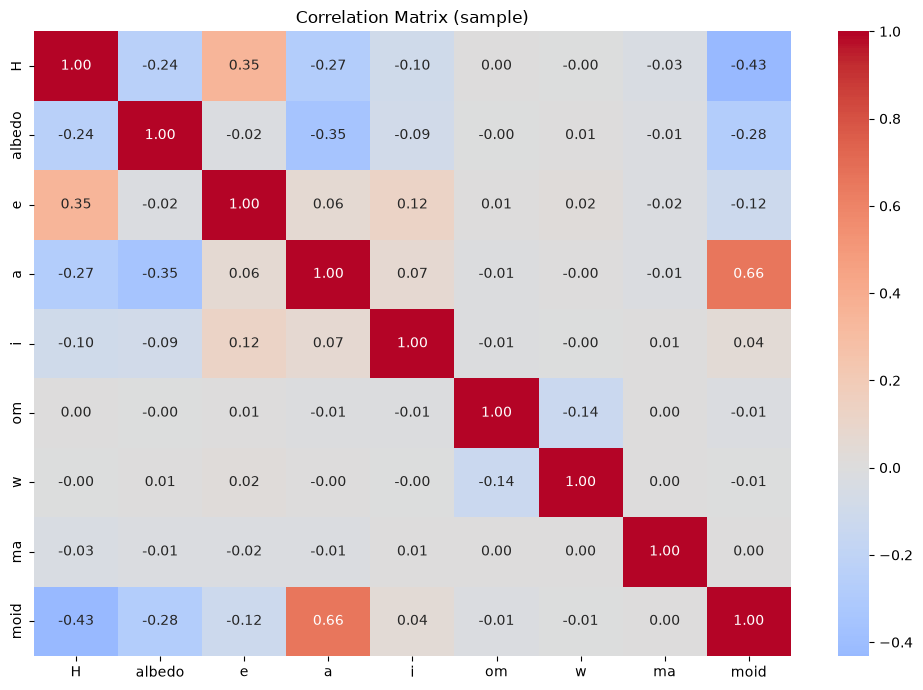

In [42]:
corr = eda_df[FEATURES + [TARGET]].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (sample)")
plt.tight_layout()
plt.show()

corr.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

## 6. เลือกตัวแปรและแบ่งชุดฝึก/ชุดทดสอบ

ใช้ `train_test_split` โดยกำหนด `test_size=0.20` และ `random_state=42` เพื่อให้แบ่งข้อมูลซ้ำได้เหมือนเดิม

**การป้องกัน Data Leakage:** ชุดทดสอบจะไม่ถูกใช้ในการฝึกหรือคำนวณค่ามัธยฐานของตัวแปรนำเข้า การประเมินจะทำหลังจากฝึกแต่ละโมเดลเสร็จแล้ว

In [43]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"ข้อมูลทั้งหมดหลังทำความสะอาด: {len(df):,}")
print(f"Training set: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Test set: {len(X_test):,} ({len(X_test)/len(df):.1%})")

ข้อมูลทั้งหมดหลังทำความสะอาด: 938,603
Training set: 750,882 (80.0%)
Test set: 187,721 (20.0%)


## 7. จำกัดจำนวนข้อมูลฝึกสำหรับโมเดลต้นไม้

ให้ Linear Regression ใช้ชุดฝึกทั้งหมด ส่วน Random Forest และ HistGradientBoosting จะใช้ข้อมูลฝึกสุ่มไม่เกิน 150,000 แถวเมื่อชุดฝึกมีขนาดใหญ่ เพื่อลดเวลาฝึก

ชุดทดสอบยังคงเดิมและไม่ถูกนำมาใช้ฝึก

In [44]:
if len(X_train) > MAX_TREE_TRAIN_ROWS:
    rng = np.random.RandomState(RANDOM_STATE)
    selected_indices = rng.choice(
        len(X_train), size=MAX_TREE_TRAIN_ROWS, replace=False
    )
    X_tree = X_train.iloc[selected_indices].copy()
    y_tree = y_train.iloc[selected_indices].copy()
else:
    X_tree = X_train.copy()
    y_tree = y_train.copy()

print(f"Linear Regression ใช้ข้อมูลฝึก: {len(X_train):,} แถว")
print(f"โมเดลต้นไม้ใช้ข้อมูลฝึก: {len(X_tree):,} แถว")
print(f"ชุดทดสอบ: {len(X_test):,} แถว")

Linear Regression ใช้ข้อมูลฝึก: 750,882 แถว
โมเดลต้นไม้ใช้ข้อมูลฝึก: 150,000 แถว
ชุดทดสอบ: 187,721 แถว


## 8. สร้างและฝึกแบบจำลอง

- **Linear Regression:** แบบจำลองพื้นฐาน ใช้ median imputation และ StandardScaler
- **Random Forest:** เรียนรู้ความสัมพันธ์ไม่เชิงเส้นจากต้นไม้หลายต้น
- **HistGradientBoosting:** Gradient Boosting แบบใช้ฮิสโตแกรม

การคำนวณ preprocessing จะอยู่ภายใน `Pipeline` เพื่อให้ imputer และ scaler ถูก fit จากข้อมูลฝึกเท่านั้น

In [45]:
linear_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

random_forest_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

hist_gradient_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=0.1,
        random_state=RANDOM_STATE
    ))
])

models = {
    "Linear Regression": (linear_pipeline, X_train, y_train),
    "Random Forest": (random_forest_pipeline, X_tree, y_tree),
    "HistGradientBoosting": (hist_gradient_pipeline, X_tree, y_tree),
}

trained_models = {}
predictions = {}
results = []

for name, (pipeline, X_fit, y_fit) in models.items():
    print(f"กำลังฝึก {name} ...")
    pipeline.fit(X_fit, y_fit)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    trained_models[name] = pipeline
    predictions[name] = y_pred
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

    print(f"เสร็จแล้ว | MAE={mae:.6f} AU | RMSE={rmse:.6f} AU | R²={r2:.6f}")

results_df = pd.DataFrame(results).sort_values("RMSE", ascending=True).reset_index(drop=True)
display(results_df)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

กำลังฝึก Linear Regression ...
เสร็จแล้ว | MAE=0.634188 AU | RMSE=2.046958 AU | R²=0.101551
กำลังฝึก Random Forest ...
เสร็จแล้ว | MAE=0.020761 AU | RMSE=0.135480 AU | R²=0.996064
กำลังฝึก HistGradientBoosting ...
เสร็จแล้ว | MAE=0.035246 AU | RMSE=0.272363 AU | R²=0.984094


,Model,MAE,RMSE,R2
0,Random Forest,0.020761,0.135480,0.996064
1,HistGradientBoosting,0.035246,0.272363,0.984094
2,Linear Regression,0.634188,2.046958,0.101551


## 9. ประเมินผลและเลือกแบบจำลอง

ตารางด้านบนแสดงผลการประเมินจากชุดทดสอบที่แยกไว้ก่อนฝึก

- **MAE:** ค่าเฉลี่ยของขนาดความผิดพลาดสัมบูรณ์ หน่วย AU; ค่ายิ่งต่ำยิ่งดี
- **RMSE:** ให้น้ำหนักกับความผิดพลาดขนาดใหญ่เพิ่มขึ้น หน่วย AU; ค่ายิ่งต่ำยิ่งดี
- **R²:** เปรียบเทียบกับการทำนายด้วยค่าเฉลี่ย โดยทั่วไปค่ายิ่งสูงยิ่งดี และอาจติดลบได้

โค้ดเลือกโมเดลที่มี RMSE ต่ำสุดให้สอดคล้องกับ `train.py` ไม่ควรกล่าวว่าโมเดลแม่นยำหรือดีที่สุดในเชิงทั่วไปจากตัวเลขเพียงอย่างเดียว ต้องพิจารณาข้อจำกัดและลักษณะชุดทดสอบด้วย

In [46]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]
best_result = results_df.iloc[0]

print("โมเดลที่เลือกตาม RMSE:", best_model_name)
print(f"MAE  = {best_result['MAE']:.6f} AU")
print(f"RMSE = {best_result['RMSE']:.6f} AU")
print(f"R²   = {best_result['R2']:.6f}")

โมเดลที่เลือกตาม RMSE: Random Forest
MAE  = 0.020761 AU
RMSE = 0.135480 AU
R²   = 0.996064


## 10. วิเคราะห์ข้อผิดพลาด (Error Analysis)

กราฟ Actual vs Predicted ช่วยเปรียบเทียบค่าจริงกับค่าทำนาย จุดที่อยู่ใกล้เส้นประหมายถึงค่าทำนายใกล้เคียงค่าจริง ส่วน Residual คือค่าจริงลบค่าทำนาย

In [47]:
error_df = pd.DataFrame({
    "Actual_MOID_AU": y_test.to_numpy(),
    "Predicted_MOID_AU": best_predictions
})
error_df["Error_AU"] = error_df["Predicted_MOID_AU"] - error_df["Actual_MOID_AU"]
error_df["Absolute_Error_AU"] = error_df["Error_AU"].abs()
error_df = error_df.sort_values("Absolute_Error_AU", ascending=False)
error_df.to_csv(OUTPUT_DIR / "prediction_errors.csv", index=False)

display(error_df.head(10))

,Actual_MOID_AU,Predicted_MOID_AU,Error_AU,Absolute_Error_AU
137086,14.3053,34.073085,19.767785,19.767785
142517,14.3893,29.489173,15.099873,15.099873
178844,13.4199,26.827830,13.407930,13.407930
102200,17.8575,30.996624,13.139124,13.139124
27951,50.4956,40.681498,-9.814102,9.814102
27053,10.2878,20.006184,9.718384,9.718384
132036,45.1942,35.974403,-9.219797,9.219797
40268,41.8794,32.731536,-9.147864,9.147864
42247,29.3352,20.814316,-8.520884,8.520884
47807,20.4262,28.935946,8.509746,8.509746


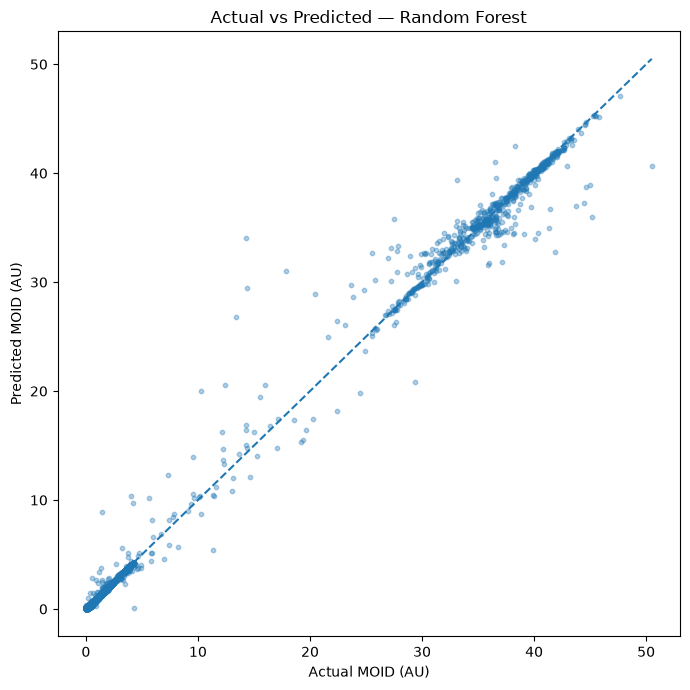

In [48]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.35, s=10)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual MOID (AU)")
plt.ylabel("Predicted MOID (AU)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

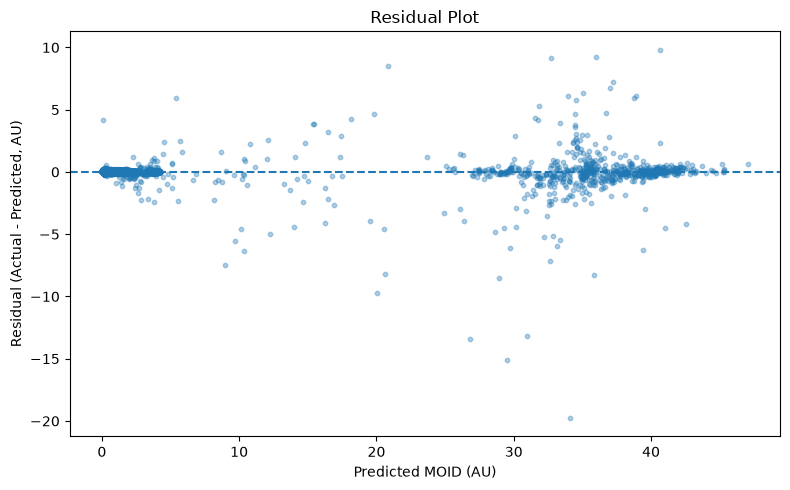

ข้อผิดพลาดสัมบูรณ์เฉลี่ย (AU): 0.020761
ค่าคลาดเคลื่อนสัมบูรณ์สูงสุด (AU): 19.767785


In [49]:
residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.35, s=10)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted MOID (AU)")
plt.ylabel("Residual (Actual - Predicted, AU)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

print("ข้อผิดพลาดสัมบูรณ์เฉลี่ย (AU):", f"{np.mean(np.abs(residuals)):.6f}")
print("ค่าคลาดเคลื่อนสัมบูรณ์สูงสุด (AU):", f"{np.max(np.abs(residuals)):.6f}")

## 11. Feature Importance

วิธีคำนวณความสำคัญขึ้นกับโมเดลที่ถูกเลือก:
- Random Forest ใช้ `feature_importances_`
- HistGradientBoosting ใช้ permutation importance บนชุดทดสอบ (สุ่มไม่เกิน 20,000 แถว)
- Linear Regression ใช้ค่าสัมบูรณ์ของ coefficient

ค่านี้ช่วยอธิบายพฤติกรรมของโมเดล แต่ไม่ได้พิสูจน์ความเป็นเหตุเป็นผล

,Feature,Importance
3,a,9.586877e-01
2,e,2.538302e-02
0,H,1.140663e-02
4,i,3.410620e-03
7,ma,5.508345e-04
6,w,3.794943e-04
5,om,1.809869e-04
1,albedo,7.278468e-07


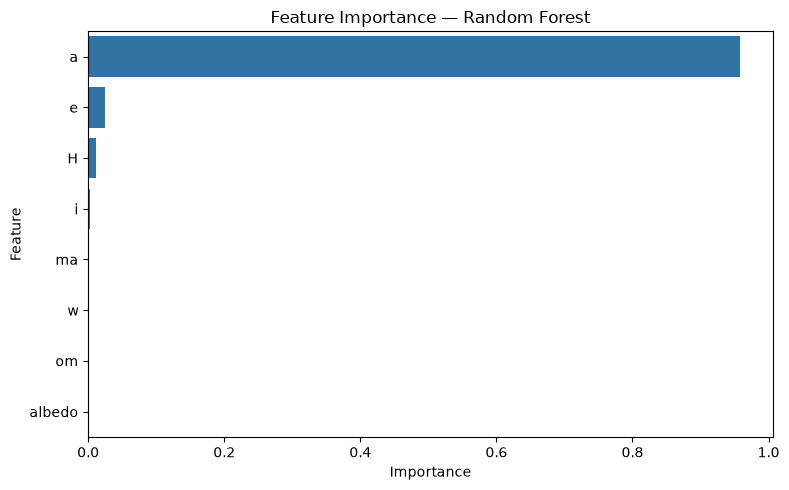

In [50]:
feature_importance_df = None

if best_model_name == "Random Forest":
    model_step = best_model.named_steps["model"]
    values = model_step.feature_importances_
    feature_importance_df = pd.DataFrame({"Feature": FEATURES, "Importance": values})

elif best_model_name == "HistGradientBoosting":
    from sklearn.inspection import permutation_importance

    if len(X_test) > 20_000:
        rng = np.random.RandomState(RANDOM_STATE)
        idx = rng.choice(len(X_test), size=20_000, replace=False)
        X_imp = X_test.iloc[idx]
        y_imp = y_test.iloc[idx]
    else:
        X_imp, y_imp = X_test, y_test

    perm = permutation_importance(
        best_model, X_imp, y_imp,
        n_repeats=3, random_state=RANDOM_STATE,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    feature_importance_df = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": perm.importances_mean
    })

else:
    model_step = best_model.named_steps["model"]
    feature_importance_df = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": np.abs(model_step.coef_)
    })

feature_importance_df = feature_importance_df.sort_values("Importance", ascending=False)
feature_importance_df.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
display(feature_importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance_df, x="Importance", y="Feature")
plt.title(f"Feature Importance — {best_model_name}")
plt.tight_layout()
plt.show()

## 12. บันทึกโมเดลและข้อมูลประกอบ

บันทึก Pipeline ของโมเดลที่เลือกลง `model/moid_model.joblib` เพื่อให้เว็บแอปใช้ preprocessing แบบเดียวกับตอนฝึก และบันทึกข้อมูลการทดลองลง `model/project_info.joblib`

ไฟล์ CSV และกราฟผลการประเมินจะถูกเก็บใน `outputs/`

In [51]:
model_path = MODEL_DIR / "moid_model.joblib"
joblib.dump(best_model, model_path)

project_info = {
    "target": TARGET,
    "target_unit": "AU",
    "features": FEATURES,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "best_model": best_model_name,
    "model_results": results_df.to_dict(orient="records"),
    "dataset_rows_after_cleaning": int(len(df)),
    "full_training_rows": int(len(X_train)),
    "training_rows_tree_models": int(len(X_tree)),
    "test_rows": int(len(X_test)),
}
joblib.dump(project_info, MODEL_DIR / "project_info.joblib")

print("บันทึกโมเดล:", model_path)
print("บันทึกข้อมูลประกอบ:", MODEL_DIR / "project_info.joblib")
print("ผลการประเมิน:", OUTPUT_DIR / "model_comparison.csv")
print("การวิเคราะห์ข้อผิดพลาด:", OUTPUT_DIR / "prediction_errors.csv")
print("Feature importance:", OUTPUT_DIR / "feature_importance.csv")

บันทึกโมเดล: model\moid_model.joblib
บันทึกข้อมูลประกอบ: model\project_info.joblib
ผลการประเมิน: outputs\model_comparison.csv
การวิเคราะห์ข้อผิดพลาด: outputs\prediction_errors.csv
Feature importance: outputs\feature_importance.csv
